In [184]:

!pip install Sastrawi

In [185]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

print("Semua library berhasil di-load")

Semua library berhasil di-load


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [186]:
df = pd.concat([
    pd.read_csv('/content/dataset_intent_gymnasyum_10000.csv'),
    pd.read_csv('/content/extra_train_data.csv'),
    pd.read_csv('/content/dataset_intent_gymnasyum_500.csv'),
], ignore_index=True)

df.head()

,message,intent
0,Tolong batalkan pemesanan sesi personal traini...,cancel
1,Booking saya hari Minggu jam berapa ya?,schedule_inquiry
2,yaudah tanggal 16 pagi aja gapapa makasih,confirmation
3,Tolong hapus jadwal akhir pekan saya,cancel
4,"loker nya rusak kak, minta dicek thanks kak",other


In [187]:
print("Jumlah Data :", len(df))

df.info()

Jumlah Data : 10650
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10650 entries, 0 to 10649
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   message  10650 non-null  object
 1   intent   10650 non-null  object
dtypes: object(2)
memory usage: 166.5+ KB


In [188]:
df.isnull().sum()

,0
message,0
intent,0


In [189]:

df = df.drop_duplicates()

print("Jumlah data setelah drop duplicate:")
print(len(df))

Jumlah data setelah drop duplicate:
10647


In [190]:

df['intent'].value_counts()

,count
intent,
cancel,2130
schedule_inquiry,2130
confirmation,2130
reschedule,2130
other,2127


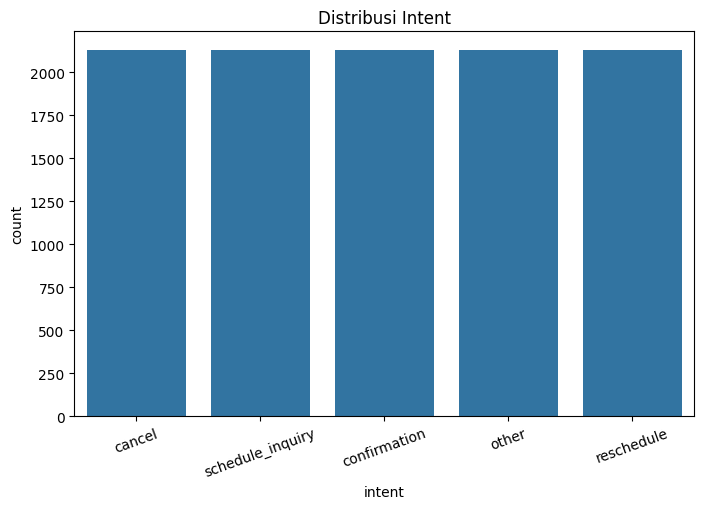

In [191]:

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='intent'
)

plt.title("Distribusi Intent")
plt.xticks(rotation=20)

plt.show()

In [192]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

stopwords_indonesia = set(stopwords.words('indonesian'))
# kata negasi membawa makna: "tidak bisa hadir", "ga usah diganti"
NEGASI = {'tidak', 'tak', 'bukan', 'jangan', 'belum', 'nggak', 'ngga', 'gak', 'ga', 'enggak'}
stopwords_indonesia -= NEGASI
stop_words = stopwords_indonesia

In [193]:
def clean_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r"http\S+", "", text)

    text = re.sub(r"www\S+", "", text)

    text = re.sub(r"@\w+", "", text)

    text = re.sub(r"#\w+", "", text)

    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    text = re.sub(r"\s+", " ", text)

    words = text.split()

    words = [
        word
        for word in words
        if word not in stopwords_indonesia
    ]

    words = [
        stemmer.stem(word)
        for word in words
    ]

    return " ".join(words)

In [230]:
test = pd.read_csv('/content/independent_test_set.csv')
QUESTION = {'apa','apakah','berapa','kapan','bagaimana','siapa','mana','bisa','boleh','ada'}

def make_clean(keep=set(), remove_stop=True, stem=True, q_token=True):
    def f(text):
        raw = str(text)
        t = raw.lower()
        t = re.sub(r"http\S+|www\S+|@\w+|#\w+", "", t)
        t = re.sub(r"[^a-zA-Z\s]", " ", t)
        words = t.split()
        if remove_stop:
            sw = stopwords_indonesia - keep
            words = [w for w in words if w not in sw]
        if stem:
            words = [stemmer.stem(w) for w in words]
        if q_token and '?' in raw:
            words.append('tandatanya')
        return " ".join(words)
    return f

variants = {
    'A: sekarang':               make_clean(q_token=False),
    'B: simpan kata tanya + ?':  make_clean(keep=QUESTION),
    'C: tanpa stopword':         make_clean(remove_stop=False),
    'D: tanpa stopword & stem':  make_clean(remove_stop=False, stem=False),
}
for name, fn in variants.items():
    Xtr = df['message'].apply(fn)
    clf = Pipeline([("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1,2))),
                    ("lr", LogisticRegression(max_iter=2000))])
    clf.fit(Xtr, df['intent'])
    pred = clf.predict(test['message'].apply(fn))
    print(f"{name:<28} akurasi test independen: {accuracy_score(test['intent'], pred):.3f}")

A: sekarang                  akurasi test independen: 0.920
B: simpan kata tanya + ?     akurasi test independen: 0.940
C: tanpa stopword            akurasi test independen: 0.980
D: tanpa stopword & stem     akurasi test independen: 0.980


In [231]:
df['clean_text'] = df['message'].apply(
    clean_text
)

In [232]:
df[['message', 'clean_text']].head()

,message,clean_text
0,Tolong batalkan pemesanan sesi personal traini...,tolong batal mesan sesi personal training jang...
1,Booking saya hari Minggu jam berapa ya?,booking minggu jam ya
2,yaudah tanggal 16 pagi aja gapapa makasih,yaudah tanggal pagi aja gapapa makasih
3,Tolong hapus jadwal akhir pekan saya,tolong hapus jadwal pekan
4,"loker nya rusak kak, minta dicek thanks kak",loker nya rusak kak cek thanks kak


In [233]:
X = df['clean_text']

y = df['intent']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [234]:
model_lr = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1,2)
        )
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=2000
        )
    )
])

In [235]:
model_lr.fit(
    X_train,
    y_train
)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=10000, ngram_range=(1, 2))),
                ('classifier', LogisticRegression(max_iter=2000))])

In [236]:
pred_lr = model_lr.predict(
    X_test
)

In [237]:
print(
    classification_report(
        y_test,
        pred_lr
    )
)

                  precision    recall  f1-score   support

          cancel       1.00      0.99      0.99       426
    confirmation       0.98      0.97      0.97       426
           other       0.99      0.99      0.99       426
      reschedule       0.99      0.97      0.98       426
schedule_inquiry       0.96      0.99      0.97       426

        accuracy                           0.98      2130
       macro avg       0.98      0.98      0.98      2130
    weighted avg       0.98      0.98      0.98      2130



In [238]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        pred_lr
    )
)

Accuracy: 0.9821596244131455


In [239]:
model_svm = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1,2)
        )
    ),

    (
        "svm",
        LinearSVC()
    )
])

In [240]:
model_svm.fit(
    X_train,
    y_train
)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=10000, ngram_range=(1, 2))),
                ('svm', LinearSVC())])

In [241]:
pred_svm = model_svm.predict(
    X_test
)

In [242]:
print(
    classification_report(
        y_test,
        pred_svm
    )
)

                  precision    recall  f1-score   support

          cancel       1.00      0.99      0.99       426
    confirmation       0.98      0.98      0.98       426
           other       0.99      0.99      0.99       426
      reschedule       1.00      0.97      0.98       426
schedule_inquiry       0.97      0.99      0.98       426

        accuracy                           0.98      2130
       macro avg       0.99      0.98      0.98      2130
    weighted avg       0.99      0.98      0.98      2130



In [243]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        pred_svm
    )
)

Accuracy: 0.9849765258215962


In [244]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(
    df['intent']
)

joblib.dump(
    encoder,
    "label_encoder.pkl"
)

['label_encoder.pkl']

In [245]:
MAX_WORDS = 10000
MAX_LEN = 50

# split dulu, baru tokenisasi
X_train_txt, X_test_txt, y_train_seq, y_test_seq = train_test_split(
    df['clean_text'], y_encoded,
    test_size=0.2, stratify=y_encoded, random_state=42
)

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_txt)          # hanya data train

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train_txt),
                            maxlen=MAX_LEN, padding='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test_txt),
                           maxlen=MAX_LEN, padding='post')

In [246]:

model = Sequential([

    tf.keras.Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128
    ),

    Bidirectional(
        LSTM(64)
    ),

    Dropout(0.3),

    Dense(
        64,
        activation='relu'
    ),

    Dense(
        len(np.unique(y_encoded)),
        activation='softmax'
    )

])

In [247]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,387,397 (5.29 MB)

 Trainable params: 1,387,397 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

In [248]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

In [249]:
early_stop = tf.keras.callbacks.EarlyStopping(

    monitor='val_loss',

    patience=3,

    restore_best_weights=True
)

In [250]:
history = model.fit(

    X_train_seq,

    y_train_seq,

    validation_split=0.2,

    epochs=20,

    batch_size=32,

    callbacks=[early_stop]
)

Epoch 1/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.7370 - loss: 0.6605 - val_accuracy: 0.9683 - val_loss: 0.1035
Epoch 2/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9723 - loss: 0.0884 - val_accuracy: 0.9836 - val_loss: 0.0596
Epoch 3/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9884 - loss: 0.0432 - val_accuracy: 0.9865 - val_loss: 0.0431
Epoch 4/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9909 - loss: 0.0311 - val_accuracy: 0.9888 - val_loss: 0.0429
Epoch 5/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9924 - loss: 0.0252 - val_accuracy: 0.9865 - val_loss: 0.0485
Epoch 6/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9952 - loss: 0.0161 - val_accuracy: 0.9883 - val_loss: 0.0457
Epoch 7/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9960 - loss: 0.0127 - val_accuracy: 0.9853 - val_loss: 0.0590


In [251]:
loss, acc = model.evaluate(
    X_test_seq,
    y_test_seq
)

print("Accuracy :", acc)

67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9845 - loss: 0.0552
Accuracy : 0.9845070242881775


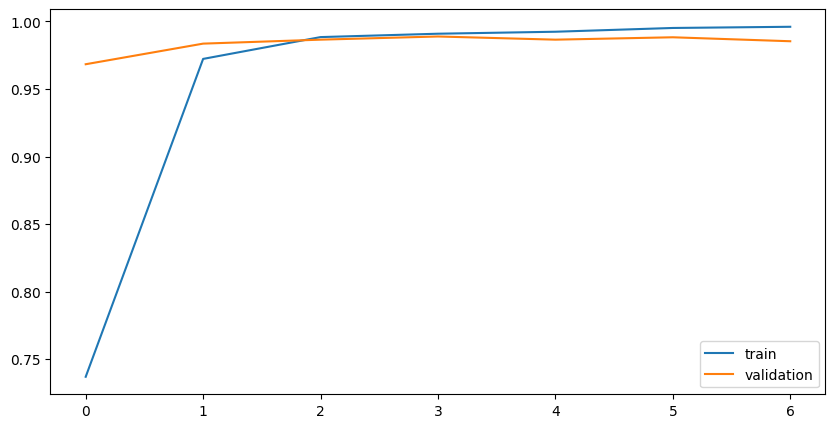

In [252]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history['accuracy'],
    label='train'
)

plt.plot(
    history.history['val_accuracy'],
    label='validation'
)

plt.legend()

plt.show()

In [253]:
pred_prob = model.predict(
    X_test_seq
)

pred_label = np.argmax(
    pred_prob,
    axis=1
)

67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


In [254]:
print(
    classification_report(
        y_test_seq,
        pred_label,
        target_names=encoder.classes_
    )
)

                  precision    recall  f1-score   support

          cancel       0.98      0.99      0.98       426
    confirmation       1.00      0.98      0.99       426
           other       0.99      0.99      0.99       426
      reschedule       0.99      0.97      0.98       426
schedule_inquiry       0.97      0.99      0.98       426

        accuracy                           0.98      2130
       macro avg       0.98      0.98      0.98      2130
    weighted avg       0.98      0.98      0.98      2130



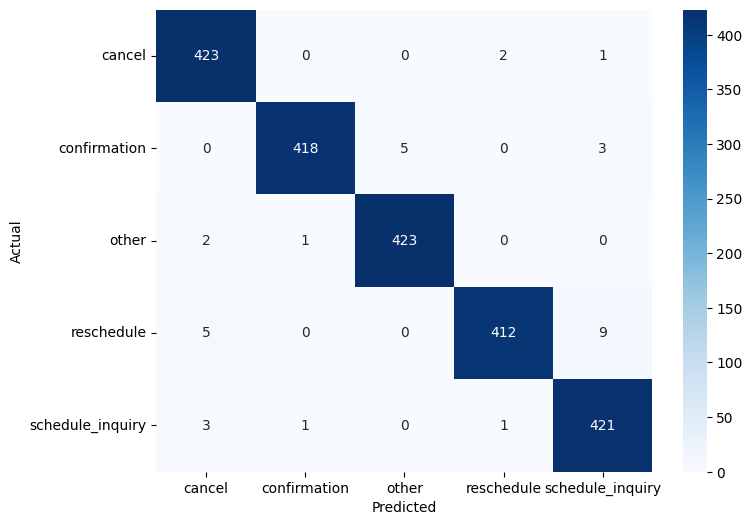

In [255]:
cm = confusion_matrix(
    y_test_seq,
    pred_label
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [256]:
model.save(
    "intent_classifier.keras"
)

In [257]:
joblib.dump(
    tokenizer,
    "tokenizer.pkl"
)

['tokenizer.pkl']

In [258]:
loss, acc = model.evaluate(
    X_test_seq,
    y_test_seq,
    verbose=0
)

print(acc)

0.9845070242881775


In [259]:
joblib.dump(
    model_lr,
    "logistic_regression.pkl"
)

joblib.dump(
    model_svm,
    "linear_svm.pkl"
)

['linear_svm.pkl']

In [260]:
history_df = pd.DataFrame(
    history.history
)

history_df.to_csv(
    "training_history.csv",
    index=False
)